In [3]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.199 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import os

print("Day 7 setup completed!")

Day 7 setup completed!


In [12]:
EPOCHS = 15
BATCH_SIZE = 32

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Epochs: 15
Batch size: 32


In [14]:
!mamba install -c emscripten-forge scikit-learn 

mambajs 0.21.4

emscripten-forge channel alias is deprecated. Please use https://prefix.dev/emscripten-forge-3x explicitely.
Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge, emscripten-forge-3x

Solving environment...
Solving took 1.237 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pysocks             1.7.1  

In [16]:
import gzip
import struct
import numpy as np

with gzip.open("train-images-idx3-ubyte.gz", "rb") as f:
    _, n, rows, cols = struct.unpack(">IIII", f.read(16))
    X_train = np.frombuffer(
        f.read(), dtype=np.uint8
    ).reshape(n, rows * cols)

with gzip.open("train-labels-idx1-ubyte.gz", "rb") as f:
    _, n = struct.unpack(">II", f.read(8))
    y_train = np.frombuffer(f.read(), dtype=np.uint8)

X_train = X_train.astype("float32") / 255.0

print(X_train.shape)
print(y_train.shape)

(60000, 784)
(60000,)


In [18]:
rng = np.random.default_rng(42)

indices = rng.choice(
    len(X_train), 10000, replace=False
)

X_train_small = X_train[indices]
y_train_small = y_train[indices]

print("Training samples:", X_train_small.shape)

Training samples: (10000, 784)


In [19]:
from sklearn.neural_network import MLPClassifier

day7_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    batch_size=BATCH_SIZE,
    max_iter=EPOCHS,
    random_state=42,
    verbose=True
)

day7_model.fit(X_train_small, y_train_small)

print("Training completed!")
print("Epochs completed:", day7_model.n_iter_)

Iteration 1, loss = 0.72501665
Iteration 2, loss = 0.49160007
Iteration 3, loss = 0.42621654
Iteration 4, loss = 0.38503247
Iteration 5, loss = 0.36059036
Iteration 6, loss = 0.33507257
Iteration 7, loss = 0.31762890
Iteration 8, loss = 0.30832380
Iteration 9, loss = 0.29108458
Iteration 10, loss = 0.27225354
Iteration 11, loss = 0.26617859
Iteration 12, loss = 0.24920755
Iteration 13, loss = 0.23172886
Iteration 14, loss = 0.22197190
Iteration 15, loss = 0.21211846


/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Training completed!
Epochs completed: 15


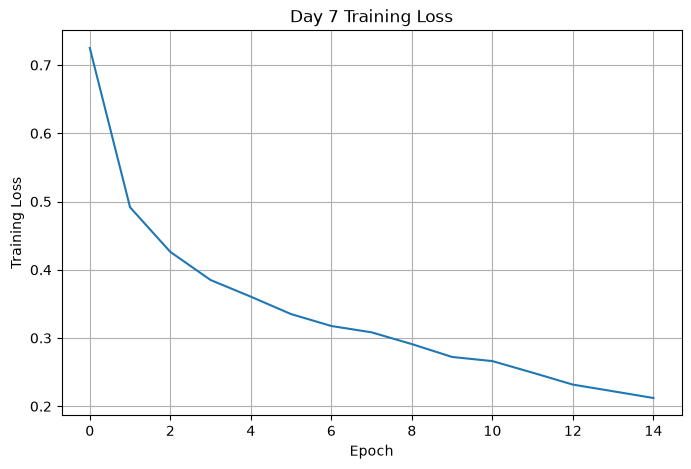

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(day7_model.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Day 7 Training Loss")
plt.grid()
plt.show()

In [21]:
rng = np.random.default_rng(42)

indices = rng.choice(len(X_train), 5000, replace=False)

X_train_small = X_train[indices]
y_train_small = y_train[indices]

print("Training samples:", X_train_small.shape)

Training samples: (5000, 784)


In [22]:
from sklearn.neural_network import MLPClassifier

day7_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    batch_size=32,
    max_iter=15,
    random_state=42,
    verbose=True
)

day7_model.fit(X_train_small, y_train_small)

print("Training completed!")
print("Epochs completed:", day7_model.n_iter_)

Iteration 1, loss = 0.86597406
Iteration 2, loss = 0.55202066
Iteration 3, loss = 0.49637134
Iteration 4, loss = 0.45220306
Iteration 5, loss = 0.43885239
Iteration 6, loss = 0.40548851
Iteration 7, loss = 0.34966519
Iteration 8, loss = 0.33435945
Iteration 9, loss = 0.32008506
Iteration 10, loss = 0.30178068
Iteration 11, loss = 0.28715868
Iteration 12, loss = 0.26787502
Iteration 13, loss = 0.26567228
Iteration 14, loss = 0.25045484
Iteration 15, loss = 0.22711847


/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Training completed!
Epochs completed: 15


In [23]:
from sklearn.neural_network import MLPClassifier

day7_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    batch_size=32,
    max_iter=15,
    random_state=42,
    verbose=True
)

day7_model.fit(X_train_small, y_train_small)

print("Training completed!")
print("Epochs completed:", day7_model.n_iter_)

Iteration 1, loss = 0.86597406
Iteration 2, loss = 0.55202066
Iteration 3, loss = 0.49637134
Iteration 4, loss = 0.45220306
Iteration 5, loss = 0.43885239
Iteration 6, loss = 0.40548851
Iteration 7, loss = 0.34966519
Iteration 8, loss = 0.33435945
Iteration 9, loss = 0.32008506
Iteration 10, loss = 0.30178068
Iteration 11, loss = 0.28715868
Iteration 12, loss = 0.26787502
Iteration 13, loss = 0.26567228
Iteration 14, loss = 0.25045484
Iteration 15, loss = 0.22711847


/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Training completed!
Epochs completed: 15


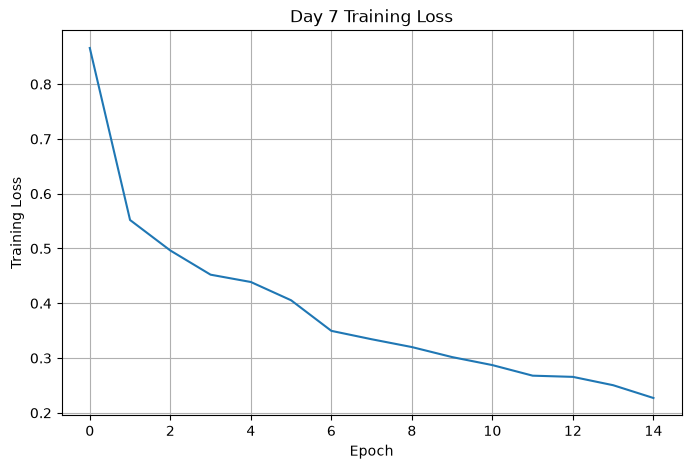

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(day7_model.loss_curve_)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Day 7 Training Loss")
plt.grid()
plt.show()

In [25]:
import gzip
import struct
import numpy as np

with gzip.open("t10k-images-idx3-ubyte.gz", "rb") as f:
    _, n, rows, cols = struct.unpack(">IIII", f.read(16))
    X_test = np.frombuffer(
        f.read(), dtype=np.uint8
    ).reshape(n, rows * cols)

with gzip.open("t10k-labels-idx1-ubyte.gz", "rb") as f:
    _, n = struct.unpack(">II", f.read(8))
    y_test = np.frombuffer(f.read(), dtype=np.uint8)

X_test = X_test.astype("float32") / 255.0

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = day7_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("DAY 7 MODEL EVALUATION")
print("----------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

DAY 7 MODEL EVALUATION
----------------------
Accuracy : 0.8385
Precision: 0.847850834910531
Recall   : 0.8385
F1 Score : 0.8399353705393896

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.63      0.74      1000
           1       0.99      0.95      0.97      1000
           2       0.74      0.72      0.73      1000
           3       0.82      0.86      0.84      1000
           4       0.70      0.78      0.74      1000
           5       0.94      0.93      0.94      1000
           6       0.58      0.70      0.64      1000
           7       0.92      0.92      0.92      1000
           8       0.97      0.94      0.96      1000
           9       0.93      0.95      0.94      1000

    accuracy                           0.84     10000
   macro avg       0.85      0.84      0.84     10000
weighted avg       0.85      0.84      0.84     10000



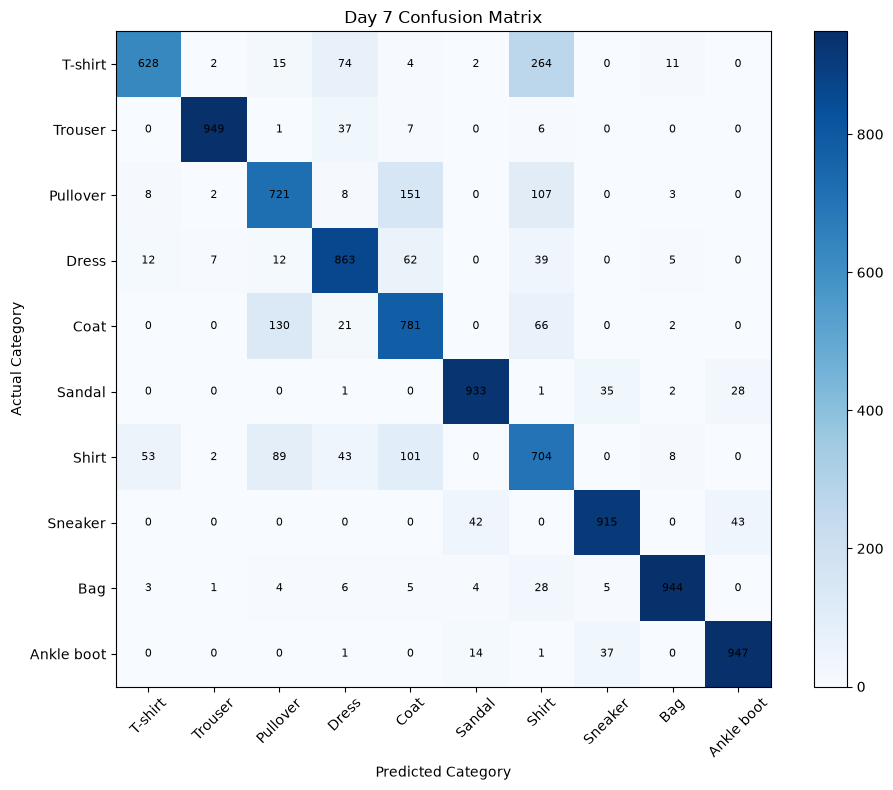

In [30]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Day 7 Confusion Matrix")
plt.colorbar()

classes = [
    "T-shirt", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 fontsize=8)

plt.tight_layout()
plt.show()


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("DAY 7 RESULTS")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

DAY 7 RESULTS
Accuracy : 0.8385
Precision: 0.847850834910531
Recall   : 0.8385
F1 Score : 0.8399353705393896


In [32]:
import os
import joblib

os.makedirs("../Models", exist_ok=True)

joblib.dump(
    day7_model,
    "../Models/day7_fashion_mlp.joblib"
)

print("Day 7 model saved!")

Day 7 model saved!


In [33]:
plt.savefig(
    "../Models/day7_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>